<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2 - Desafio Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

# Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    classification_report
)

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_palette("deep")
np.random.seed(42)

# Explicación de los datos

### Carga de data

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
sample_submission_df = pd.read_csv('sample_submission.csv')

### Inspección básica de data

In [3]:
train_df.head(3)

,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [5]:
test_df.head(3)

,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [6]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    21829 non-null  int64  
 1   pub_fecha             21829 non-null  object 
 2   pub_titulo            21829 non-null  object 
 3   pub_descripcion       21829 non-null  object 
 4   pub_monto_estimado    10230 non-null  float64
 5   pub_moneda            10226 non-null  object 
 6   pub_metodo            21734 non-null  object 
 7   pub_modalidad         21829 non-null  object 
 8   pub_n_items           21829 non-null  int64  
 9   pub_cantidad_total    21829 non-null  float64
 10  pub_categoria         21828 non-null  object 
 11  pub_categoria_id      21828 non-null  float64
 12  pub_n_categorias      21829 non-null  int64  
 13  pub_inicio            21829 non-null  object 
 14  pub_cierre            21823 non-null  object 
 15  pub_dias_postulacio

In [7]:
sample_submission_df.head(3)

,id,y_desierta
0,47254358932,1
1,295671198916,1
2,214756376398,1


In [8]:
sample_submission_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          21829 non-null  int64
 1   y_desierta  21829 non-null  int64
dtypes: int64(2)
memory usage: 341.2 KB


In [9]:
sample_submission_df[sample_submission_df["y_desierta"] == 1].sum()

id            10929193504546743
y_desierta                21829
dtype: int64

### ¿El conjunto de entrenamiento está desbalanceado?

In [10]:
train_df.value_counts('y_desierta')

y_desierta
0    122006
1     30547
Name: count, dtype: int64

In [11]:
train_df["y_desierta"].value_counts(normalize=True) * 100

y_desierta
0    79.976139
1    20.023861
Name: proportion, dtype: float64

### El conjunto de entrenamiento está desbalanceado.
Se tiene un desbalance respecto de la variable objetivo. Debido a que se tiene una proporción de 4:1. Dónde por **cada licitación desierta** (clase 1) hay **4 licitaciones no desiertas** (clase 0).

### ¿Cuántos valores nulos hay?

In [12]:
train_df.isnull().sum()

id                          0
pub_fecha                   0
pub_titulo                  9
pub_descripcion             9
pub_monto_estimado      67266
pub_moneda              67302
pub_metodo                 68
pub_modalidad               0
pub_n_items                 0
pub_cantidad_total          0
pub_categoria              25
pub_categoria_id           25
pub_n_categorias            0
pub_inicio                  0
pub_cierre                 27
pub_dias_postulacion       23
pub_tiene_consultas         0
pub_dias_consultas         68
comprador                   0
comprador_id                0
comprador_rut              35
region                     10
direccion                8196
y_desierta                  0
dtype: int64

In [13]:
100 * 67266 / 152553 

44.09352815087215

pub_monto_estimado y pub_moneda tienen alrededor del 44% de valores nulos respecto del total de registros.

### ¿Existirá una relación entre los montos nulos respecto de las monedas?

In [14]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


Hay 67.266 registros con montos nulos y monedas nulas.

In [15]:
resumen = train_df.groupby(
    "pub_moneda", dropna=False
)["pub_monto_estimado"].agg(
    total="size",
    nulos=lambda x: x.isna().sum(),
    porcentaje_nulos=lambda x: x.isna().mean() * 100
)

resumen.sort_values("porcentaje_nulos", ascending=False)

,total,nulos,porcentaje_nulos
pub_moneda,,,
NaN,67302,67266,99.94651
CLF,623,0,0.00000
CLP,84116,0,0.00000
EUR,2,0,0.00000
USD,510,0,0.00000


Todos los registros con montos nulos tienen monedas nulas. Mientras que, hay monedas nulas que pertenecen a registros con montos no nulos.

### ¿Existirá una relación entre los montos nulos respecto de las categorías?

In [16]:
resumen = train_df.groupby("pub_categoria")["pub_monto_estimado"].agg(
    total="size",
    nulos=lambda x: x.isna().sum(),
    porcentaje_nulos=lambda x: x.isna().mean() * 100
)

resumen[resumen["porcentaje_nulos"] == 100].sort_values(
    "total", ascending=False
)

,total,nulos,porcentaje_nulos
pub_categoria,,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,190,100.0
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,105,100.0
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,85,100.0
Obras / Obras Mayores / Obra Civil / 2da,77,77,100.0
Consultoria / Consultoria / Inspecciones / 1a S,71,71,100.0
...,...,...,...
"Equipamiento y suministros médicos / Productos quirúrgicos / Instrumentos endoscópicos, suministros, accesorios y productos relacionados / Extractores endoscópicos",1,1,100.0
"Equipamiento y suministros médicos / Productos quirúrgicos / Instrumentos endoscópicos, suministros, accesorios y productos relacionados / Puntas endoscópicas de irrigación o succión o sondas de coagulación o accesorios",1,1,100.0
"Equipamiento y suministros médicos / Productos quirúrgicos / Instrumentos quirúrgicos de corte, trampas y productos relacionados / Fórceps quirúrgicos para cortar huesos",1,1,100.0


Hay 1362 categorías con solamente registros con montos nulos.

### ¿Qué relación existirá entre los montos y la variable objetivo?

In [17]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["y_desierta"],
    normalize="index"
) * 100

y_desierta,0,1
pub_monto_estimado,,
False,79.977019,20.022981
True,79.975025,20.024975


In [18]:
train_df.groupby(
    ["pub_categoria", train_df["pub_monto_estimado"].isna()]
)["y_desierta"].agg(
    cantidad="count",
    tasa_desierta="mean"
).assign(
    tasa_desierta=lambda x: x["tasa_desierta"] * 100
)

cantidad  \
pub_categoria                                      pub_monto_estimado             
Alimentos, bebidas y tabaco / Aceites y grasas ... False                     29   
                                                   True                      27   
Alimentos, bebidas y tabaco / Aceites y grasas ... False                      1   
                                                   True                       1   
Alimentos, bebidas y tabaco / Aceites y grasas ... True                       1   
...                                                                         ...   
Vehículos y equipamiento en general / Vehículos... True                      73   
Vehículos y equipamiento en general / Vehículos... False                    151   
                                                   True                     185   
Vehículos y equipamiento en general / Vehículos... False                     34   
                                                   True                      30   

                                                                       tasa_desierta  
pub_categoria                                      pub_monto_estimado                 
Alimentos, bebidas y tabaco / Aceites y grasas ... False                   10.344828  
                                                   True                    11.111111  
Alimentos, bebidas y tabaco / Aceites y grasas ... False                    0.000000  
                                                   True                     0.000000  
Alimentos, bebidas y tabaco / Aceites y grasas ... True                     0.000000  
...                                                                              ...  
Vehículos y equipamiento en general / Vehículos... True                    31.506849  
Vehículos y equipamiento en general / Vehículos... False                   35.761589  
                                                   True                    42.702703  
Vehículos y equipamiento en general / Vehículos... False                   52.941176  
                                                   True                    20.000000  

[12671 rows x 2 columns]

### Separación de variables

In [19]:
X = train_df.drop(columns=["y_desierta"])
y = train_df["y_desierta"]

print("X:", X.shape)
print("y:", y.shape)

X: (152553, 23)
y: (152553,)


### Verificación de fechas inválidas

In [20]:
datos = train_df.copy()

datos["pub_fecha"] = pd.to_datetime(
    datos["pub_fecha"],
    dayfirst=True,
    errors="coerce"
)

print("Fechas inválidas:", datos["pub_fecha"].isna().sum())

C:\Users\User\AppData\Local\Temp\ipykernel_16924\3707854381.py:3: UserWarning: Parsing dates in %Y-%m-%dT%H:%M:%S%z format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  datos["pub_fecha"] = pd.to_datetime(


Fechas inválidas: 0


Al no haber fechas inválidas, podemos crear nuevas variables a partir de la fecha de publicación. Por ejemplo, podemos extraer el año, mes y día de la semana de la fecha de publicación.

In [21]:
train = datos[
    datos["pub_fecha"] < "2024-10-01"
].copy()

val = datos[
    datos["pub_fecha"] >= "2024-10-01"
].copy()

print("Entrenamiento:", train.shape)
print("Validación:", val.shape)

Entrenamiento: (116666, 24)
Validación: (35887, 24)


# Construcción de features

La pauta indica que la señal más importante está en el texto, el historial del comprador, la rareza del rubro y los plazos. Por eso se construyen features en cuatro grupos:

- **Texto:** título y descripción concatenados, luego vectorizados con TF-IDF.
- **Plazos y estructura:** cantidades, número de ítems, días de postulación/consultas, fecha, monto y flags de faltantes.
- **Comprador:** volumen histórico y tasa histórica de licitaciones desiertas.
- **Rubro:** volumen histórico y tasa histórica por categoría.

Para evitar mirar el futuro, el historial usado en validación se calcula solo con licitaciones anteriores al 2024-10-01. En el entrenamiento interno, las tasas históricas se calculan de forma acumulada y excluyen la propia fila.

### Preparación de características sin fuga temporal

In [22]:
BASE_NUMERICAS = [
    "pub_n_items",
    "pub_cantidad_total",
    "pub_n_categorias",
    "pub_dias_postulacion",
    "pub_dias_consultas",
    "pub_monto_estimado",
    "monto_log1p",
    "monto_nulo",
    "moneda_nula",
    "titulo_largo",
    "descripcion_larga",
    "texto_palabras",
    "mes_publicacion",
    "dia_semana_publicacion",
    "cat_niveles"
]

HISTORICAS = [
    "hist_comprador_n",
    "hist_comprador_tasa",
    "hist_categoria_n",
    "hist_categoria_tasa",
    "hist_comprador_categoria_n",
    "hist_comprador_categoria_tasa",
    "comprador_nuevo",
    "categoria_nueva"
]

NUMERICAS = BASE_NUMERICAS + HISTORICAS

CATEGORICAS = [
    "pub_metodo",
    "pub_modalidad",
    "pub_moneda",
    "region",
    "categoria_principal"
]

TARGET = "y_desierta"
SMOOTHING = 20

def normalizar_llave(serie):
    return serie.fillna("desconocido").astype(str)

def crear_features_base(df):
    X = df.copy()

    X["pub_fecha"] = pd.to_datetime(X["pub_fecha"], errors="coerce", utc=True)
    X["texto"] = (
        X["pub_titulo"].fillna("").astype(str) + " " +
        X["pub_descripcion"].fillna("").astype(str)
    )

    X["titulo_largo"] = X["pub_titulo"].fillna("").astype(str).str.len()
    X["descripcion_larga"] = X["pub_descripcion"].fillna("").astype(str).str.len()
    X["texto_palabras"] = X["texto"].str.split().str.len()

    X["monto_nulo"] = X["pub_monto_estimado"].isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)
    X["pub_monto_estimado"] = pd.to_numeric(X["pub_monto_estimado"], errors="coerce")
    X["monto_log1p"] = np.log1p(X["pub_monto_estimado"].clip(lower=0))

    X["mes_publicacion"] = X["pub_fecha"].dt.month
    X["dia_semana_publicacion"] = X["pub_fecha"].dt.dayofweek

    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1

    for col in ["pub_n_items", "pub_cantidad_total", "pub_n_categorias",
                "pub_dias_postulacion", "pub_dias_consultas"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)

    X["comprador_key"] = normalizar_llave(X["comprador_id"])
    X["categoria_key"] = normalizar_llave(X["pub_categoria_id"])
    X["comprador_categoria_key"] = X["comprador_key"] + "|" + X["categoria_key"]
    return X

def agregar_historial_acumulado(df, keys, prefijo, global_rate):
    ordenado = df.sort_values("pub_fecha").copy()
    grupos = ordenado.groupby(keys, dropna=False)[TARGET]
    previos = grupos.cumcount()
    positivos_previos = grupos.cumsum() - ordenado[TARGET]
    ordenado[f"hist_{prefijo}_n"] = np.log1p(previos)
    ordenado[f"hist_{prefijo}_tasa"] = (
        (positivos_previos + SMOOTHING * global_rate) /
        (previos + SMOOTHING)
    )
    return ordenado[[f"hist_{prefijo}_n", f"hist_{prefijo}_tasa"]].reindex(df.index)

def agregar_historial_desde_referencia(df, referencia, keys, prefijo, global_rate):
    resumen = referencia.groupby(keys, dropna=False)[TARGET].agg(["count", "sum"])
    resumen[f"hist_{prefijo}_n"] = np.log1p(resumen["count"])
    resumen[f"hist_{prefijo}_tasa"] = (
        (resumen["sum"] + SMOOTHING * global_rate) /
        (resumen["count"] + SMOOTHING)
    )

    X = df.join(resumen[[f"hist_{prefijo}_n", f"hist_{prefijo}_tasa"]], on=keys)
    X[f"hist_{prefijo}_n"] = X[f"hist_{prefijo}_n"].fillna(0)
    X[f"hist_{prefijo}_tasa"] = X[f"hist_{prefijo}_tasa"].fillna(global_rate)
    return X[[f"hist_{prefijo}_n", f"hist_{prefijo}_tasa"]]

def construir_features(df, referencia=None):
    X = crear_features_base(df)

    if referencia is None:
        global_rate = X[TARGET].mean()
        X[["hist_comprador_n", "hist_comprador_tasa"]] = agregar_historial_acumulado(
            X, ["comprador_key"], "comprador", global_rate
        )
        X[["hist_categoria_n", "hist_categoria_tasa"]] = agregar_historial_acumulado(
            X, ["categoria_key"], "categoria", global_rate
        )
        X[["hist_comprador_categoria_n", "hist_comprador_categoria_tasa"]] = agregar_historial_acumulado(
            X, ["comprador_categoria_key"], "comprador_categoria", global_rate
        )
    else:
        ref = crear_features_base(referencia)
        global_rate = ref[TARGET].mean()
        X[["hist_comprador_n", "hist_comprador_tasa"]] = agregar_historial_desde_referencia(
            X, ref, ["comprador_key"], "comprador", global_rate
        )
        X[["hist_categoria_n", "hist_categoria_tasa"]] = agregar_historial_desde_referencia(
            X, ref, ["categoria_key"], "categoria", global_rate
        )
        X[["hist_comprador_categoria_n", "hist_comprador_categoria_tasa"]] = agregar_historial_desde_referencia(
            X, ref, ["comprador_categoria_key"], "comprador_categoria", global_rate
        )

    X["comprador_nuevo"] = (X["hist_comprador_n"] == 0).astype(int)
    X["categoria_nueva"] = (X["hist_categoria_n"] == 0).astype(int)

    columnas_modelo = NUMERICAS + CATEGORICAS + ["texto"]
    return X[columnas_modelo]

X_train = construir_features(train)
X_val = construir_features(val, referencia=train)

y_train = train[TARGET].astype(int)
y_val = val[TARGET].astype(int)

print("Features entrenamiento:", X_train.shape)
print("Features validación:", X_val.shape)
X_train.head()

Features entrenamiento: (116666, 29)
Features validación: (35887, 29)


,pub_n_items,pub_cantidad_total,pub_n_categorias,pub_dias_postulacion,pub_dias_consultas,pub_monto_estimado,monto_log1p,monto_nulo,moneda_nula,titulo_largo,...,hist_comprador_categoria_n,hist_comprador_categoria_tasa,comprador_nuevo,categoria_nueva,pub_metodo,pub_modalidad,pub_moneda,region,categoria_principal,texto
0,1,1.0,1,17.769,11.0,NaN,NaN,1,1,27,...,0.000000,0.200204,0,0,open,Licitación Pública MOP (O1),desconocido,Región Aysén del General Carlos Ibáñez del Campo,Obras MINVU,LP04-2024 AV. UNO SUR AYSEN CONSTRUCCIÓN CALZA...
1,1,1.0,1,25.230,21.0,NaN,NaN,1,1,61,...,1.386294,0.261047,0,0,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),desconocido,Región Metropolitana de Santiago,Servicios de construcción y mantenimiento,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...
2,55,12150.0,27,6.032,3.0,3500000.0,15.068274,0,0,45,...,0.000000,0.200204,0,1,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región del Maule,Equipamiento para laboratorios,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM ...
3,1,350.0,1,6.234,1.0,5327035.0,15.488306,0,0,15,...,2.079442,0.296447,0,0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región Metropolitana de Santiago,Equipamiento y suministros médicos,GASA HIDROFILA SC 309 - SP 742 IDDOC 718225...
5,4,935.0,2,5.931,2.0,10000000.0,16.118096,0,0,46,...,1.098612,0.227458,0,0,open,Licitación Pública Entre 100 y 1000 UTM (LE),CLP,Región de la Araucanía,"Artículos para estructuras, obras y construcci...",ADQUISICION DE PLANCHAS VARIAS DE CONSTRUCCION...


### Pipelines de preprocesamiento

In [23]:
def crear_one_hot():
    try:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=20)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore")

def crear_preprocesamiento(incluir_texto=True, incluir_historial=True):
    numericas = NUMERICAS if incluir_historial else BASE_NUMERICAS

    transformadores = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), numericas),
        ("cat", crear_one_hot(), CATEGORICAS)
    ]

    if incluir_texto:
        transformadores.append(
            ("texto", TfidfVectorizer(
                max_features=20000,
                min_df=5,
                ngram_range=(1, 2),
                sublinear_tf=True
            ), "texto")
        )

    return ColumnTransformer(transformadores)

preprocesamiento_full = crear_preprocesamiento(incluir_texto=True, incluir_historial=True)
preprocesamiento_estructural = crear_preprocesamiento(incluir_texto=False, incluir_historial=False)
preprocesamiento_sin_historial = crear_preprocesamiento(incluir_texto=True, incluir_historial=False)

# Modelos explorados

Se comparan tres familias para distinguir el aporte de cada bloque de features:

- Un **árbol estructural** similar al benchmark descrito en la pauta, sin texto ni historial.
- Un **bosque aleatorio estructural**, para capturar interacciones no lineales en variables tabulares.
- Una **regresión logística con texto e historial**, que suele ser fuerte en problemas con texto disperso y permite ajustar el peso de la clase minoritaria.

La comparación se hace con una partición temporal: entrenamiento antes del 2024-10-01 y validación desde esa fecha en adelante.

In [24]:
def mejor_umbral_f1(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    idx = int(np.nanargmax(f1))
    return thresholds[idx], f1[idx], precision[idx], recall[idx]

def evaluar_pipeline(nombre, pipeline, X_tr, y_tr, X_va, y_va):
    pipeline.fit(X_tr, y_tr)
    proba = pipeline.predict_proba(X_va)[:, 1]
    threshold, f1_opt, precision_opt, recall_opt = mejor_umbral_f1(y_va, proba)
    pred_05 = (proba >= 0.5).astype(int)
    pred_opt = (proba >= threshold).astype(int)

    return {
        "modelo": nombre,
        "pipeline": pipeline,
        "threshold": threshold,
        "f1_05": f1_score(y_va, pred_05),
        "f1_opt": f1_score(y_va, pred_opt),
        "precision_opt": precision_score(y_va, pred_opt, zero_division=0),
        "recall_opt": recall_score(y_va, pred_opt, zero_division=0),
        "ap": average_precision_score(y_va, proba),
        "roc_auc": roc_auc_score(y_va, proba),
        "matriz_confusion": confusion_matrix(y_va, pred_opt)
    }

modelos_base = {
    "arbol_estructural": Pipeline([
        ("pre", preprocesamiento_estructural),
        ("clf", DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=100,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "bosque_estructural": Pipeline([
        ("pre", preprocesamiento_estructural),
        ("clf", RandomForestClassifier(
            n_estimators=250,
            max_depth=14,
            min_samples_leaf=50,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ]),
    "logistica_texto_sin_historial": Pipeline([
        ("pre", preprocesamiento_sin_historial),
        ("clf", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            solver="liblinear",
            max_iter=1000,
            random_state=42
        ))
    ]),
    "logistica_texto_historial": Pipeline([
        ("pre", preprocesamiento_full),
        ("clf", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            solver="liblinear",
            max_iter=1000,
            random_state=42
        ))
    ])
}

resultados_base = [
    evaluar_pipeline(nombre, clone(modelo), X_train, y_train, X_val, y_val)
    for nombre, modelo in modelos_base.items()
]

tabla_base = (
    pd.DataFrame(resultados_base)
    .drop(columns=["pipeline", "matriz_confusion"])
    .sort_values("f1_opt", ascending=False)
)
tabla_base

,modelo,threshold,f1_05,f1_opt,precision_opt,recall_opt,ap,roc_auc
3,logistica_texto_historial,0.453926,0.380793,0.388534,0.293400,0.574965,0.344752,0.661597
2,logistica_texto_sin_historial,0.438029,0.365466,0.374729,0.267524,0.625313,0.323421,0.641898
1,bosque_estructural,0.491528,0.367734,0.369862,0.245164,0.752712,0.291056,0.623229
0,arbol_estructural,0.480781,0.355223,0.358620,0.229579,0.818915,0.265873,0.593119


# Búsqueda de hiperparámetros

La búsqueda usa la misma validación temporal. No se usa validación cruzada aleatoria, porque mezclaría licitaciones de meses posteriores dentro del ajuste de meses anteriores. El objetivo es maximizar F1 en la clase positiva y elegir un umbral explícito sobre probabilidades.

In [25]:
grillas = {
    "arbol_estructural": {
        "modelo": modelos_base["arbol_estructural"],
        "params": {
            "clf__max_depth": [6, 10, 14, 18],
            "clf__min_samples_leaf": [50, 100, 200],
            "clf__class_weight": [None, "balanced"]
        }
    },
    "logistica_texto_historial": {
        "modelo": modelos_base["logistica_texto_historial"],
        "params": {
            "clf__C": [0.3, 1.0, 3.0],
            "clf__class_weight": [None, "balanced"]
        }
    }
}

resultados_busqueda = []

for nombre, spec in grillas.items():
    for params in ParameterGrid(spec["params"]):
        candidato = clone(spec["modelo"]).set_params(**params)
        resultado = evaluar_pipeline(nombre, candidato, X_train, y_train, X_val, y_val)
        resultado["params"] = params
        resultados_busqueda.append(resultado)

tabla_busqueda = (
    pd.DataFrame(resultados_busqueda)
    .drop(columns=["pipeline", "matriz_confusion"])
    .sort_values("f1_opt", ascending=False)
    .reset_index(drop=True)
)

tabla_busqueda.head(10)

,modelo,threshold,f1_05,f1_opt,precision_opt,recall_opt,ap,roc_auc,params
0,logistica_texto_historial,0.184201,0.138403,0.399508,0.302776,0.587065,0.356106,0.673436,"{'clf__C': 0.3, 'clf__class_weight': None}"
1,logistica_texto_historial,0.460282,0.390812,0.396187,0.298332,0.589569,0.353660,0.671501,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
2,logistica_texto_historial,0.155733,0.155148,0.391654,0.277209,0.667038,0.349549,0.666024,"{'clf__C': 1.0, 'clf__class_weight': None}"
3,logistica_texto_historial,0.453926,0.380793,0.388534,0.293400,0.574965,0.344752,0.661597,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
4,logistica_texto_historial,0.148435,0.177985,0.384954,0.273488,0.649791,0.337483,0.654881,"{'clf__C': 3.0, 'clf__class_weight': None}"
5,logistica_texto_historial,0.372905,0.371430,0.380109,0.266971,0.659666,0.329837,0.648405,"{'clf__C': 3.0, 'clf__class_weight': 'balanced'}"
6,arbol_estructural,0.432325,0.356892,0.362591,0.230047,0.855494,0.267068,0.593196,"{'clf__class_weight': 'balanced', 'clf__max_de..."
7,arbol_estructural,0.196721,0.066275,0.361899,0.231221,0.832267,0.267798,0.598628,"{'clf__class_weight': None, 'clf__max_depth': ..."
8,arbol_estructural,0.432325,0.334161,0.361757,0.229286,0.856745,0.273860,0.597825,"{'clf__class_weight': 'balanced', 'clf__max_de..."
9,arbol_estructural,0.518699,0.361491,0.361491,0.234887,0.784145,0.261366,0.598855,"{'clf__class_weight': 'balanced', 'clf__max_de..."


In [26]:
mejor_idx = int(pd.DataFrame(resultados_busqueda)["f1_opt"].idxmax())
mejor_resultado = resultados_busqueda[mejor_idx]
mejor_modelo = mejor_resultado["pipeline"]
mejor_threshold = mejor_resultado["threshold"]

print("Mejor modelo:", mejor_resultado["modelo"])
print("Mejores parámetros:", mejor_resultado["params"])
print(f"Umbral elegido: {mejor_threshold:.4f}")
print(f"F1 validación: {mejor_resultado['f1_opt']:.4f}")
print(f"Precision: {mejor_resultado['precision_opt']:.4f}")
print(f"Recall: {mejor_resultado['recall_opt']:.4f}")
print("Matriz de confusión:")
print(mejor_resultado["matriz_confusion"])

Mejor modelo: logistica_texto_historial
Mejores parámetros: {'clf__C': 0.3, 'clf__class_weight': None}
Umbral elegido: 0.1842
F1 validación: 0.3995
Precision: 0.3028
Recall: 0.5871
Matriz de confusión:
[[18977  9720]
 [ 2969  4221]]


              precision    recall  f1-score   support

 no desierta       0.86      0.66      0.75     28697
    desierta       0.30      0.59      0.40      7190

    accuracy                           0.65     35887
   macro avg       0.58      0.62      0.57     35887
weighted avg       0.75      0.65      0.68     35887



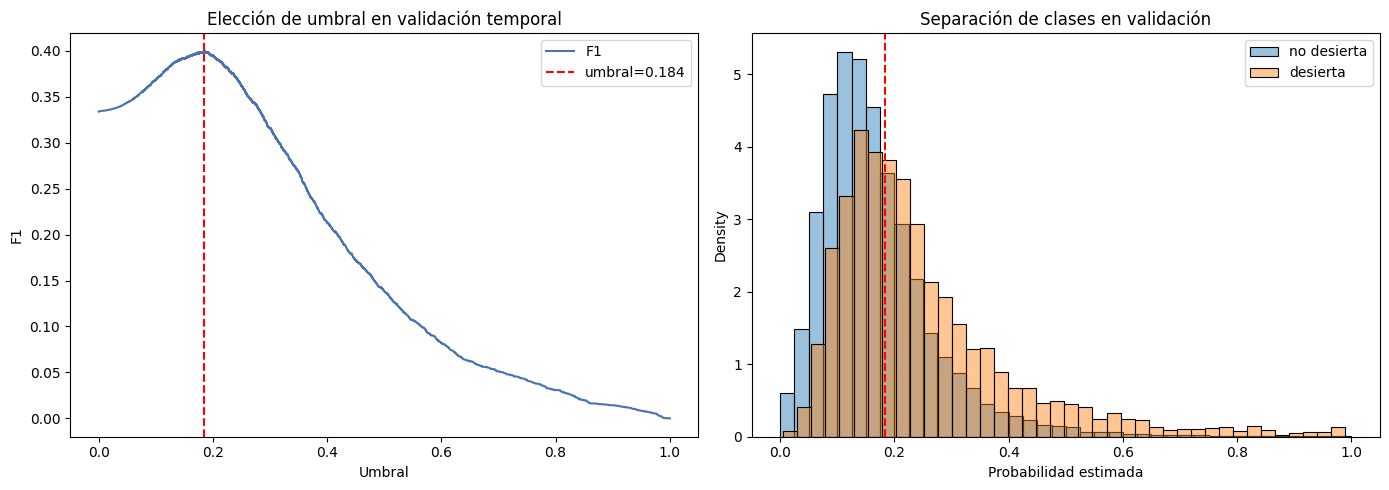

In [27]:
proba_val = mejor_modelo.predict_proba(X_val)[:, 1]
pred_val = (proba_val >= mejor_threshold).astype(int)

print(classification_report(y_val, pred_val, target_names=["no desierta", "desierta"], zero_division=0))

precision, recall, thresholds = precision_recall_curve(y_val, proba_val)
f1_curve = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(thresholds, f1_curve, label="F1")
ax[0].axvline(mejor_threshold, color="red", linestyle="--", label=f"umbral={mejor_threshold:.3f}")
ax[0].set_xlabel("Umbral")
ax[0].set_ylabel("F1")
ax[0].set_title("Elección de umbral en validación temporal")
ax[0].legend()

sns.histplot(proba_val[y_val == 0], bins=40, stat="density", color="tab:blue", alpha=0.45, label="no desierta", ax=ax[1])
sns.histplot(proba_val[y_val == 1], bins=40, stat="density", color="tab:orange", alpha=0.45, label="desierta", ax=ax[1])
ax[1].axvline(mejor_threshold, color="red", linestyle="--")
ax[1].set_xlabel("Probabilidad estimada")
ax[1].set_title("Separación de clases en validación")
ax[1].legend()
plt.tight_layout()

# Resultados y discusión

La tabla anterior permite discutir tres puntos exigidos por la pauta:

1. **Aporte del texto:** si la regresión logística con TF-IDF supera al árbol estructural, el título y la descripción contienen señal que no aparece en monto, plazos o región.
2. **Aporte del historial:** la diferencia entre la logística con y sin historial estima cuánto ayudan el comprador y el rubro. Estas variables se suavizan con la prevalencia global para no sobreajustar compradores o categorías con pocos casos.
3. **Umbral:** Kaggle evalúa etiquetas con F1, no probabilidades. Por eso se selecciona el umbral que maximiza F1 en validación temporal, en vez de usar automáticamente 0.5.

Los errores del modelo deben interpretarse con cuidado. Un falso positivo puede sugerir revisar una licitación que finalmente sí recibió ofertas; un falso negativo es más costoso operativamente, porque el organismo no anticipa una licitación que quedará desierta. Con el modelo en la mano, un comprador podría priorizar revisión de bases, plazos, montos y difusión en licitaciones con alta probabilidad estimada de quedar desiertas.

## Entrenamiento final y archivo de submission

Una vez elegido el modelo y el umbral con validación temporal, se reentrena con todo 2024. Para las licitaciones de 2025, los historiales se calculan usando solamente 2024, que es información anterior al conjunto de prueba.

In [28]:
datos_2024 = datos.copy()
test_features = construir_features(test_df, referencia=datos_2024)
X_2024 = construir_features(datos_2024)
y_2024 = datos_2024[TARGET].astype(int)

modelo_final = clone(mejor_modelo)
modelo_final.fit(X_2024, y_2024)

proba_test = modelo_final.predict_proba(test_features)[:, 1]
pred_test = (proba_test >= mejor_threshold).astype(int)

submission = pd.DataFrame({
    "id": test_df["id"],
    "y_desierta": pred_test
})

submission.to_csv("submission_pregunta2.csv", index=False)
submission["y_desierta"].value_counts(normalize=True).rename("proporcion_predicha")

y_desierta
0    0.539374
1    0.460626
Name: proporcion_predicha, dtype: float64

In [29]:
submission.head()

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,1
4,899379189128,1


El archivo `submission_pregunta2.csv` queda listo para subir a Kaggle con las columnas exigidas: `id` y `y_desierta`. El umbral usado proviene de validación temporal y no del leaderboard público.